In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [29]:
df = pd.read_csv("advertising.csv")

df.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


In [30]:
print("Shape of dataset:", df.shape)

print("\nColumns:")
print(df.columns)

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Shape of dataset: (200, 4)

Columns:
Index(['TV', 'Radio', 'Newspaper', 'Sales'], dtype='str')

Data types:
TV           float64
Radio        float64
Newspaper    float64
Sales        float64
dtype: object

Missing values:
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

Duplicate rows:
0


In [31]:
X = df[['TV', 'Radio', 'Newspaper']]
y = df['Sales']

print("Input features:")
print(X.head())

print("\nTarget:")
print(y.head())

Input features:
      TV  Radio  Newspaper
0  230.1   37.8       69.2
1   44.5   39.3       45.1
2   17.2   45.9       69.3
3  151.5   41.3       58.5
4  180.8   10.8       58.4

Target:
0    22.1
1    10.4
2    12.0
3    16.5
4    17.9
Name: Sales, dtype: float64


In [32]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (160, 3)
Testing data: (40, 3)


In [33]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Model training completed.")

Model training completed.


In [34]:
y_pred = model.predict(X_test)

print("Actual Sales vs Predicted Sales")

results = pd.DataFrame({
    'Actual Sales': y_test.values,
    'Predicted Sales': y_pred
})

print(results.head(10))

Actual Sales vs Predicted Sales
   Actual Sales  Predicted Sales
0          16.9        17.034772
1          22.4        20.409740
2          21.4        23.723989
3           7.3         9.272785
4          24.7        21.682719
5          12.6        12.569402
6          22.3        21.081195
7           8.4         8.690350
8          16.5        17.237013
9          16.1        16.666575


In [35]:
new_budget = pd.DataFrame({
    'TV': [150],
    'Radio': [20],
    'Newspaper': [30]
})

predicted_sales = model.predict(new_budget)

print("Predicted Sales:", predicted_sales[0])

Predicted Sales: 15.039523680317231


In [36]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("R² Score:", r2)

Mean Absolute Error (MAE): 1.2748262109549338
Mean Squared Error (MSE): 2.9077569102710896
Root Mean Squared Error (RMSE): 1.7052146229349223
R² Score: 0.9059011844150826


In [37]:
coefficients = pd.DataFrame({
    'Advertising Medium': ['TV', 'Radio', 'Newspaper'],
    'Coefficient': model.coef_
})

print(coefficients)
print("\nIntercept:", model.intercept_)

  Advertising Medium  Coefficient
0                 TV     0.054509
1              Radio     0.100945
2          Newspaper     0.004337

Intercept: 4.714126402214127


In [38]:
strongest = coefficients.loc[
    coefficients['Coefficient'].abs().idxmax()
]

weakest = coefficients.loc[
    coefficients['Coefficient'].abs().idxmin()
]

print("Strongest impact:", strongest['Advertising Medium'])
print("Least impact:", weakest['Advertising Medium'])

Strongest impact: Radio
Least impact: Newspaper


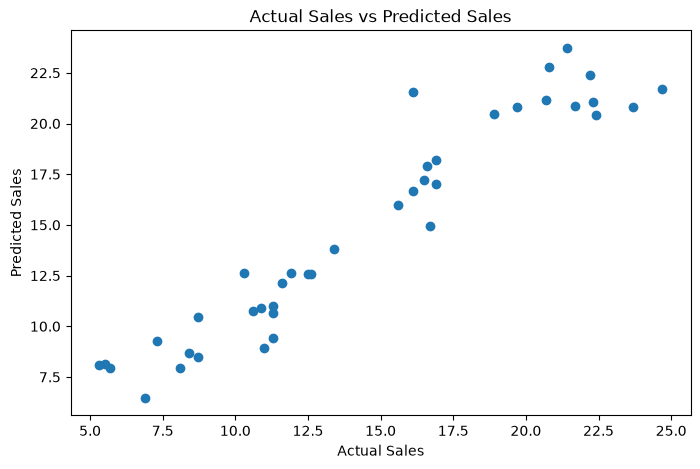

In [39]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual Sales vs Predicted Sales")

plt.show()

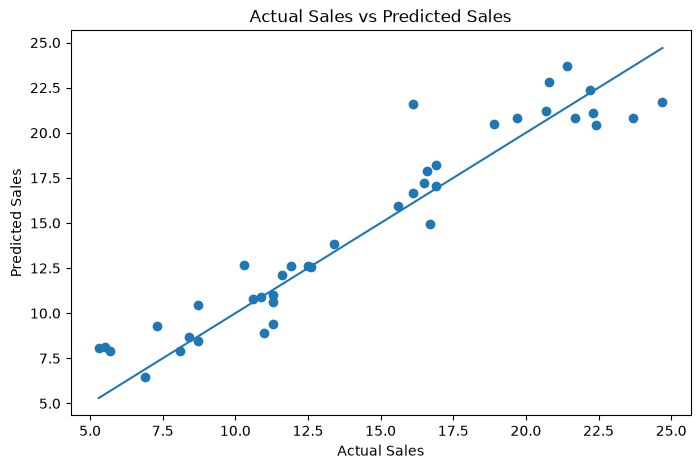

In [40]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()]
)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual Sales vs Predicted Sales")

plt.show()

## Conclusion

A Multiple Linear Regression model was built to predict product sales using TV, Radio, and Newspaper advertising spends. The model was trained on historical data and tested on unseen data.

The model was also used to predict sales for a budget of TV = 150, Radio = 20, and Newspaper = 30.

Based on the model coefficients, TV advertising has the strongest impact on sales, while Newspaper has the least impact.

### Business Recommendation
The company should give more importance to TV advertising because it has the strongest positive impact on sales.

### Technical Improvement
Prediction accuracy can be improved by trying advanced models such as Random Forest or Gradient Boosting and using cross-validation.